<a href="https://colab.research.google.com/github/keondreblankson/WEEK8/blob/main/WEEK8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 Assignment 6: Titanic Data Analysis
Keondre Blankson

In this assignment, I will explore the Titanic passenger dataset.
I want to see how survival rates differed by passenger class and sex,
and look at the ages of the passengers. I will load the data directly
from an online source, handle missing values, create new columns,
and make charts to explore the data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
df.info()

print("\nMissing values in each column:")
display(df.isna().sum())

print("\nSummary statistics:")
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB

Missing values in each column:


,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0



Summary statistics:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Cleaning the Data

I will keep the columns needed for this analysis. Some passengers
have missing ages, so I will replace those values with the median
of the recorded ages. I will also keep a column showing which ages
were originally missing. The age chart will only use recorded ages
so the replacement values do not distort the chart.

I will not automatically delete matching rows because different
passengers could have the same values in these columns.

In [3]:
columns = [
    "survived", "pclass", "sex", "age",
    "sibsp", "parch", "fare"
]

clean_df = df[columns].copy()

# Record which ages were missing before filling them.
clean_df["age_was_missing"] = clean_df["age"].isna()

median_age = clean_df["age"].median()
clean_df["age"] = clean_df["age"].fillna(median_age)

# Standardize the text values.
clean_df["sex"] = clean_df["sex"].str.strip().str.lower()

print("Ages replaced:", clean_df["age_was_missing"].sum())
print("Median age used:", median_age)

print("\nMissing values after cleaning:")
display(clean_df.isna().sum())

Ages replaced: 177
Median age used: 28.0

Missing values after cleaning:


,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
age_was_missing,0


## Transforming the Data

I will create a family size column by adding the number of siblings,
spouses, parents, and children traveling with each passenger, plus
the passenger. I will also change the passenger class numbers into
labels that are easier to read. Then I will group the data to
calculate survival percentages.

In [4]:
clean_df["family_size"] = (
    clean_df["sibsp"] + clean_df["parch"] + 1
)

class_labels = {
    1: "First class",
    2: "Second class",
    3: "Third class"
}

clean_df["passenger_class"] = clean_df["pclass"].map(class_labels)

# Survived is 1 for survivors and 0 for others.
# Its mean multiplied by 100 gives the survival percentage.
survival_by_sex = (
    clean_df.groupby("sex")["survived"].mean() * 100
)

survival_by_class = (
    clean_df.groupby("passenger_class")["survived"]
    .mean()
    .reindex(["First class", "Second class", "Third class"])
    * 100
)

print("Survival percentage by sex:")
display(survival_by_sex.round(2))

print("\nSurvival percentage by passenger class:")
display(survival_by_class.round(2))

print("\nAverage family size:")
print(round(clean_df["family_size"].mean(), 2))

Survival percentage by sex:


,survived
sex,
female,74.20
male,18.89



Survival percentage by passenger class:


,survived
passenger_class,
First class,62.96
Second class,47.28
Third class,24.24



Average family size:
1.9


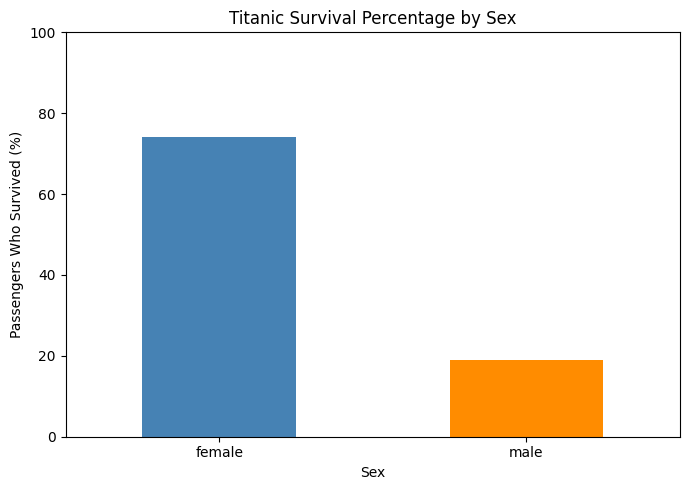

In [5]:
survival_by_sex.plot(
    kind="bar",
    color=["steelblue", "darkorange"],
    figsize=(7, 5)
)

plt.title("Titanic Survival Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Passengers Who Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

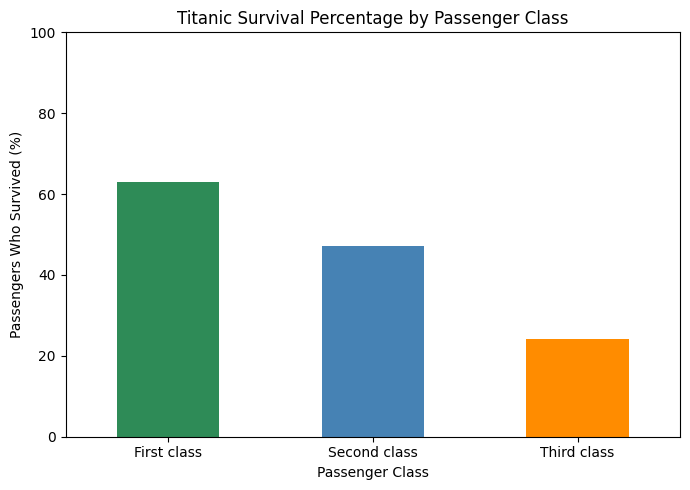

In [6]:
survival_by_class.plot(
    kind="bar",
    color=["seagreen", "steelblue", "darkorange"],
    figsize=(7, 5)
)

plt.title("Titanic Survival Percentage by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Passengers Who Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

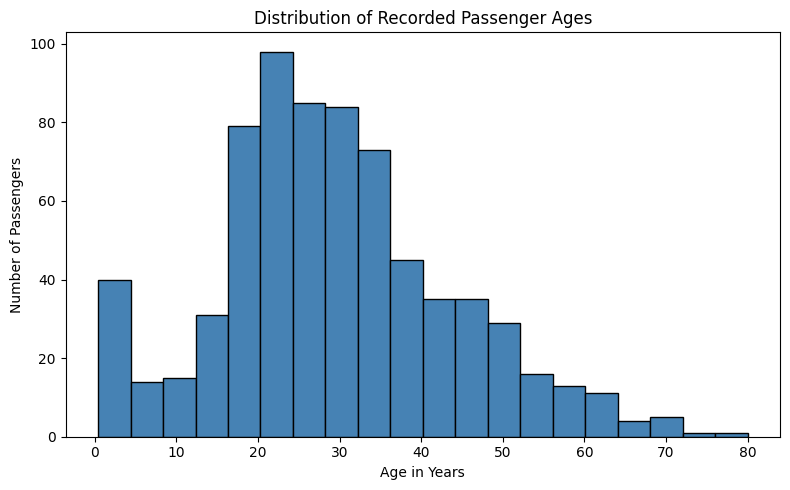

In [7]:
recorded_ages = clean_df.loc[
    ~clean_df["age_was_missing"], "age"
]

plt.figure(figsize=(8, 5))
plt.hist(
    recorded_ages,
    bins=20,
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of Recorded Passenger Ages")
plt.xlabel("Age in Years")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

## Conclusion

From this analysis, I found that female passengers had a higher
survival percentage than male passengers. First-class passengers
also had a higher survival percentage than second- and third-class
passengers. The age chart showed that many passengers with recorded
ages were young adults.

Cleaning and grouping the data made these patterns easier to see.
However, some ages were missing, so the age chart does not represent
every passenger. These comparisons show relationships in this
dataset, but they do not prove that one factor alone caused a
passenger to survive.

## Data Source

Titanic dataset from the Seaborn data repository:
https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv